# Разбор ошибок baseline

## 1. Границы диагностики

Читаем сохраненные test-прогнозы 08 и те же validation-пороги. Модели не
переобучаем, пороги не подбираем, новые исключения не вводим. Разрезы заранее
выбраны для описания: аэропорт, месяц C40 UTC, missing / unseen typecode.
Январь–май 2023 не составляют полный год; последний месяц наблюдается частично.

Сравниваем две модели при разных фиксированных validation-порогах. Поэтому
разница TP / FP не является изолированным эффектом добавления типов самолета.
AP описывает ранжирование без порога, Brier — вероятности. Частота GoA влияет
на уровень AP; внутри аэропорта показываем собственную частоту метки.
Небольшие группы не получают отдельного статистического вывода по одной цифре.

Это анализ уже просмотренного test. Его выводы не используются для настройки;
следующий подбор потребует нового независимого финального периода. Историческая
доступность признаков остается условной, EGCC в test отсутствует.

In [1]:
from pathlib import Path
import os,hashlib,json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from sklearn.metrics import average_precision_score,roc_auc_score
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd().resolve()
while not (ROOT/'reports/baseline_verification.json').exists():
    if ROOT==ROOT.parent:raise FileNotFoundError('Сначала выполните 08_baseline.ipynb')
    ROOT=ROOT.parent
R=ROOT/'reports';F=ROOT/'figures';LOCAL=ROOT/'data'
def sha(path):
    h=hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
audit=json.loads((R/'baseline_verification.json').read_text(encoding='utf-8'))
selection_path=R/'baseline_frozen_selection.json';selection_hash=sha(selection_path)
selection=json.loads(selection_path.read_text(encoding='utf-8'))
prediction_path=LOCAL/'08_test_predictions.parquet'
assert sha(prediction_path)==audit['prediction_sha256']
d=pq.read_table(prediction_path).to_pandas()
assert d.source_row.is_unique and d.source_row.is_monotonic_increasing
assert len(d)==audit['rows_test'] and int(d.GoA.sum())==audit['goa_test']
names=['geometry','geometry_aircraft'];colors={'geometry':'#00897B','geometry_aircraft':'#D65A4A'}
thresholds={n:selection['chosen'][n]['threshold'] for n in names}
for n in names:
    d[n+'_alert']=d[n].ge(thresholds[n]);d[n+'_sqerror']=(d[n]-d.GoA.astype(int))**2
d['month']=d.C40_CROSS_TIME.dt.strftime('%Y-%m')
plt.rcParams.update({'figure.dpi':120,'font.size':11,'axes.spines.top':False,
 'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
def save(name):
    plt.tight_layout()
    for ext in ['png','svg']:plt.savefig(F/f'{name}.{ext}',bbox_inches='tight')
    plt.show()


## 2. Метаданные тех же test-записей

Порядковые номера строк привязаны к SHA256 исходного финального parquet.
Сопоставляем их точно, без предположения об уникальности flight_id. Сведения
используются только для диагностики групп; исходные значения не изменяются.

In [2]:
entry=next(x for x in json.loads((R/'verification.json').read_text(encoding='utf-8'))['inputs'] if x['stage']=='final')
DATA=Path(os.environ.get('SAMPLE_SELECTION_DATA_ROOT',ROOT.parents[1]))/entry['file'].replace(chr(92),'/')
if not DATA.exists():DATA=LOCAL/'06_05_cases_excluded.parquet'
assert sha(DATA)==audit['input_sha256']
target=d.source_row.to_numpy();pieces=[];offset=0
reader=pq.ParquetFile(DATA)
for batch in reader.iter_batches(batch_size=200000,columns=['airport','C40_CROSS_TIME','GoA','typecode','icaoaircrafttype']):
    left=np.searchsorted(target,offset);right=np.searchsorted(target,offset+batch.num_rows)
    if right>left:
        a=batch.to_pandas().iloc[target[left:right]-offset].copy()
        a['source_row']=target[left:right];pieces.append(a)
    offset+=batch.num_rows
del reader
a=pd.concat(pieces,ignore_index=True);del pieces
assert np.array_equal(a.source_row,d.source_row)
assert a.airport.equals(d.airport) and a.C40_CROSS_TIME.equals(d.C40_CROSS_TIME) and a.GoA.equals(d.GoA)
vocab=json.loads((R/'preparation_train_vocabulary.json').read_text(encoding='utf-8'))['vocabulary']
for field in ['typecode','icaoaircrafttype']:
    raw=a[field];missing=raw.isna()|raw.eq('').fillna(False)
    d[field+'_state']=np.select([missing,raw.isin(vocab[field])],['missing','seen'],default='unseen')
del a
def measure(frame,n):
    y=frame.GoA.to_numpy(dtype=bool);p=frame[n].to_numpy();alert=frame[n+'_alert'].to_numpy()
    tp=int((alert&y).sum());fp=int((alert&~y).sum());fn=int((~alert&y).sum());tn=int((~alert&~y).sum());P=int(y.sum())
    return {'rows':len(frame),'goa':P,'prevalence':P/len(frame),
            'AP':float(average_precision_score(y,p)) if P else np.nan,
            'ROC_AUC':float(roc_auc_score(y,p)) if 0<P<len(frame) else np.nan,
            'Brier':float(frame[n+'_sqerror'].mean()),'mean_probability':float(p.mean()),
            'tp':tp,'fp':fp,'fn':fn,'tn':tn,'recall':tp/P if P else np.nan,
            'precision':tp/(tp+fp) if tp+fp else np.nan,'alert_rate':(tp+fp)/len(frame),
            'fp_per_1000':1000*fp/len(frame),'false_share_of_alerts':fp/(tp+fp) if tp+fp else np.nan,
            'fp_per_tp':fp/tp if tp else np.nan,'threshold':thresholds[n]}
tables={}
for field in ['airport','month','typecode_state','icaoaircrafttype_state']:
    rows=[]
    for value,frame in d.groupby(field,observed=True):
        for n in names:rows.append({'group':value,'model':n,**measure(frame,n)})
    tables[field]=pd.DataFrame(rows);tables[field].to_csv(R/f'errors_by_{field}.csv',index=False)
display(tables['month'].style.format(precision=4))
display(tables['typecode_state'].style.format(precision=4))


,group,model,rows,goa,prevalence,AP,ROC_AUC,Brier,mean_probability,tp,fp,fn,tn,recall,precision,alert_rate,fp_per_1000,false_share_of_alerts,fp_per_tp,threshold
0,2023-01,geometry,121919,414,0.0034,0.0040,0.5534,0.0034,0.0028,164,35173,250,86332,0.3961,0.0046,0.2898,288.4948,0.9954,214.4695,0.0033
1,2023-01,geometry_aircraft,121919,414,0.0034,0.0048,0.5670,0.0034,0.0028,7,2111,407,119394,0.0169,0.0033,0.0174,17.3148,0.9967,301.5714,0.0047
2,2023-02,geometry,87198,244,0.0028,0.0031,0.5540,0.0028,0.0029,99,29733,145,57221,0.4057,0.0033,0.3421,340.9826,0.9967,300.3333,0.0033
3,2023-02,geometry_aircraft,87198,244,0.0028,0.0035,0.5769,0.0028,0.0029,2,1453,242,85501,0.0082,0.0014,0.0167,16.6632,0.9986,726.5000,0.0047
4,2023-03,geometry,107375,379,0.0035,0.0044,0.5780,0.0035,0.0029,183,38837,196,68159,0.4828,0.0047,0.3634,361.6950,0.9953,212.2240,0.0033
5,2023-03,geometry_aircraft,107375,379,0.0035,0.0046,0.5810,0.0035,0.0029,12,1907,367,105089,0.0317,0.0063,0.0179,17.7602,0.9937,158.9167,0.0047
6,2023-04,geometry,112793,330,0.0029,0.0035,0.5514,0.0029,0.0029,150,41173,180,71290,0.4545,0.0036,0.3664,365.0315,0.9964,274.4867,0.0033
7,2023-04,geometry_aircraft,112793,330,0.0029,0.0035,0.5669,0.0029,0.0030,4,2050,326,110413,0.0121,0.0019,0.0182,18.1749,0.9981,512.5000,0.0047
8,2023-05,geometry,117292,372,0.0032,0.0039,0.5718,0.0032,0.0029,172,42432,200,74488,0.4624,0.0040,0.3632,361.7638,0.9960,246.6977,0.0033
9,2023-05,geometry_aircraft,117292,372,0.0032,0.0043,0.5735,0.0032,0.0029,10,1979,362,114941,0.0269,0.0050,0.0170,16.8724,0.9950,197.9000,0.0047


,group,model,rows,goa,prevalence,AP,ROC_AUC,Brier,mean_probability,tp,fp,fn,tn,recall,precision,alert_rate,fp_per_1000,false_share_of_alerts,fp_per_tp,threshold
0,missing,geometry,23297,84,0.0036,0.0045,0.5952,0.0036,0.0030,52,10065,32,13148,0.6190,0.0051,0.4343,432.0299,0.9949,193.5577,0.0033
1,missing,geometry_aircraft,23297,84,0.0036,0.0044,0.5928,0.0036,0.0032,0,32,84,23181,0.0000,0.0000,0.0014,1.3736,1.0000,nan,0.0047
2,seen,geometry,523252,1655,0.0032,0.0037,0.5602,0.0032,0.0029,716,177278,939,344319,0.4326,0.0040,0.3402,338.8004,0.9960,247.5950,0.0033
3,seen,geometry_aircraft,523252,1655,0.0032,0.0040,0.5707,0.0032,0.0029,35,9468,1620,512129,0.0211,0.0037,0.0182,18.0945,0.9963,270.5143,0.0047
4,unseen,geometry,28,0,0.0000,nan,nan,0.0000,0.0029,0,5,0,23,nan,0.0000,0.1786,178.5714,1.0000,nan,0.0033
5,unseen,geometry_aircraft,28,0,0.0000,nan,nan,0.0000,0.0028,0,0,0,28,nan,nan,0.0000,0.0000,nan,nan,0.0047


## 3. Совпадение тревог и пропущенные GoA

Совместные состояния дают полный баланс: обе модели, только geometry,
только geometry_aircraft, ни одна. Они описывают текущие validation-пороги,
не перебор порогов на test. Публикуем только агрегаты, не идентификаторы рейсов.

,GoA,alert_overlap,rows
0,False,aircraft_only,1484
1,False,both,8016
2,False,geometry_only,179332
3,False,neither,356006
4,True,aircraft_only,6
5,True,both,29
6,True,geometry_only,739
7,True,neither,965


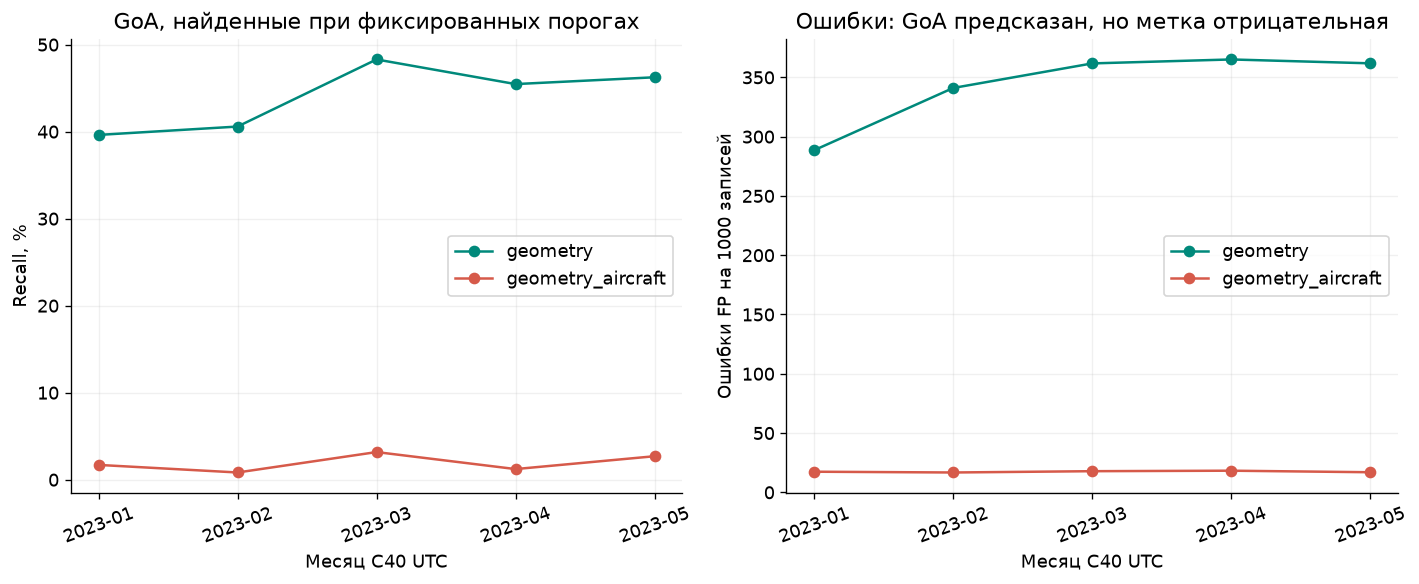

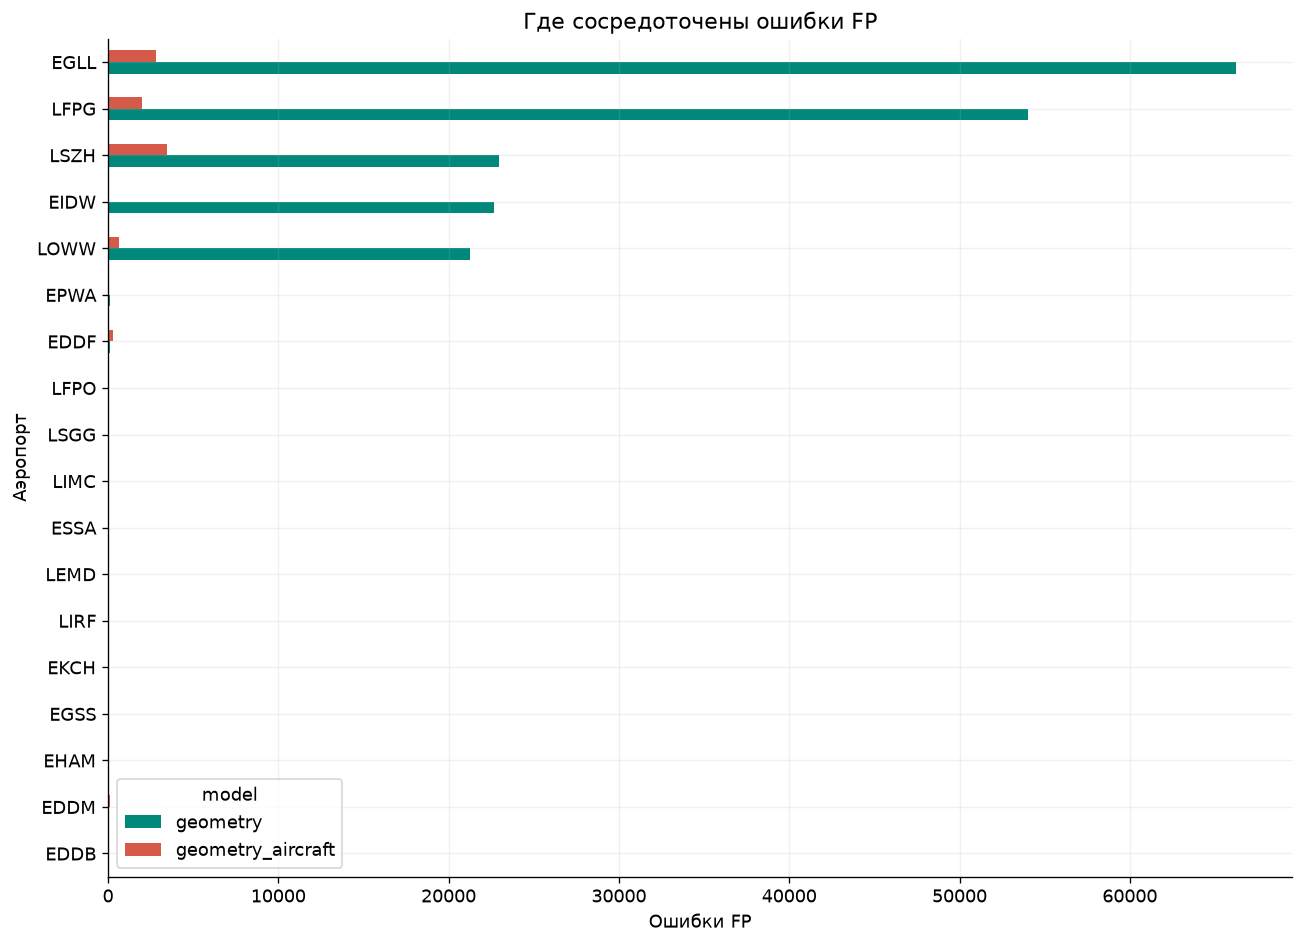

In [3]:
d['alert_overlap']=np.select([d.geometry_alert&d.geometry_aircraft_alert,
 d.geometry_alert&~d.geometry_aircraft_alert,~d.geometry_alert&d.geometry_aircraft_alert],
 ['both','geometry_only','aircraft_only'],default='neither')
joint=d.groupby(['GoA','alert_overlap']).size().rename('rows').reset_index()
joint.to_csv(R/'errors_alert_overlap.csv',index=False);display(joint)
positive=d[d.GoA].groupby(['airport','month','alert_overlap']).size().rename('rows').reset_index()
positive.to_csv(R/'errors_positive_overlap_groups.csv',index=False)
airport=tables['airport'];month=tables['month']
fig,axes=plt.subplots(1,2,figsize=(12,5))
for n in names:
    q=month[month.model.eq(n)].sort_values('group')
    axes[0].plot(q.group,100*q.recall,'o-',label=n,color=colors[n])
    axes[1].plot(q.group,q.fp_per_1000,'o-',label=n,color=colors[n])
axes[0].set(ylabel='Recall, %',title='GoA, найденные при фиксированных порогах')
axes[1].set(ylabel='Ошибки FP на 1000 записей',title='Ошибки: GoA предсказан, но метка отрицательная')
for ax in axes:ax.set_xlabel('Месяц C40 UTC');ax.tick_params(axis='x',rotation=20);ax.legend()
save('28_errors_by_month')
q=airport.pivot(index='group',columns='model',values='fp').sort_values('geometry')
q.plot.barh(figsize=(11,8),color=[colors[n] for n in q.columns])
plt.xlabel('Ошибки FP');plt.ylabel('Аэропорт');plt.title('Где сосредоточены ошибки FP')
save('29_errors_false_alerts_airports')


## 4. Разница ранжирования и вероятностей по аэропортам

AP внутри аэропорта не складывается в pooled AP. Не приписываем глобальное
изменение AP одному аэропорту арифметически. Для Brier такое разложение точное:
вес аэропорта в test умножается на разницу средних квадратов ошибок.
Отрицательный вклад означает меньший Brier у geometry_aircraft. Это описание,
не причинное объяснение. Отдельных доверительных интервалов по аэропортам
здесь нет; сравнение по знаку не объявляется статистически значимым.

,airport,rows,goa,prevalence,geometry_AP,aircraft_AP,delta_AP,delta_Brier,test_weight,Brier_contribution
0,EDDB,20511.000000,75.000000,0.003657,0.003104,0.003153,0.000050,0.000001,0.037526,0.000000
1,EDDF,11521.000000,31.000000,0.002691,0.003563,0.002984,-0.000579,0.000000,0.021078,0.000000
2,EDDM,43247.000000,113.000000,0.002613,0.002802,0.003307,0.000505,-0.000000,0.079123,-0.000000
3,EGLL,72121.000000,305.000000,0.004229,0.004014,0.004167,0.000153,0.000000,0.131950,0.000000
4,EGSS,21930.000000,62.000000,0.002827,0.004476,0.002872,-0.001604,0.000001,0.040122,0.000000
5,EHAM,11615.000000,42.000000,0.003616,0.003342,0.006360,0.003018,-0.000000,0.021250,-0.000000
6,EIDW,32534.000000,113.000000,0.003473,0.003823,0.003632,-0.000190,0.000000,0.059523,0.000000
7,EKCH,3647.000000,9.000000,0.002468,0.003091,0.003767,0.000676,-0.000000,0.006672,-0.000000
8,EPWA,19600.000000,59.000000,0.003010,0.002610,0.005308,0.002698,-0.000001,0.035860,-0.000000
9,ESSA,23351.000000,66.000000,0.002826,0.002844,0.004006,0.001162,-0.000000,0.042722,-0.000000


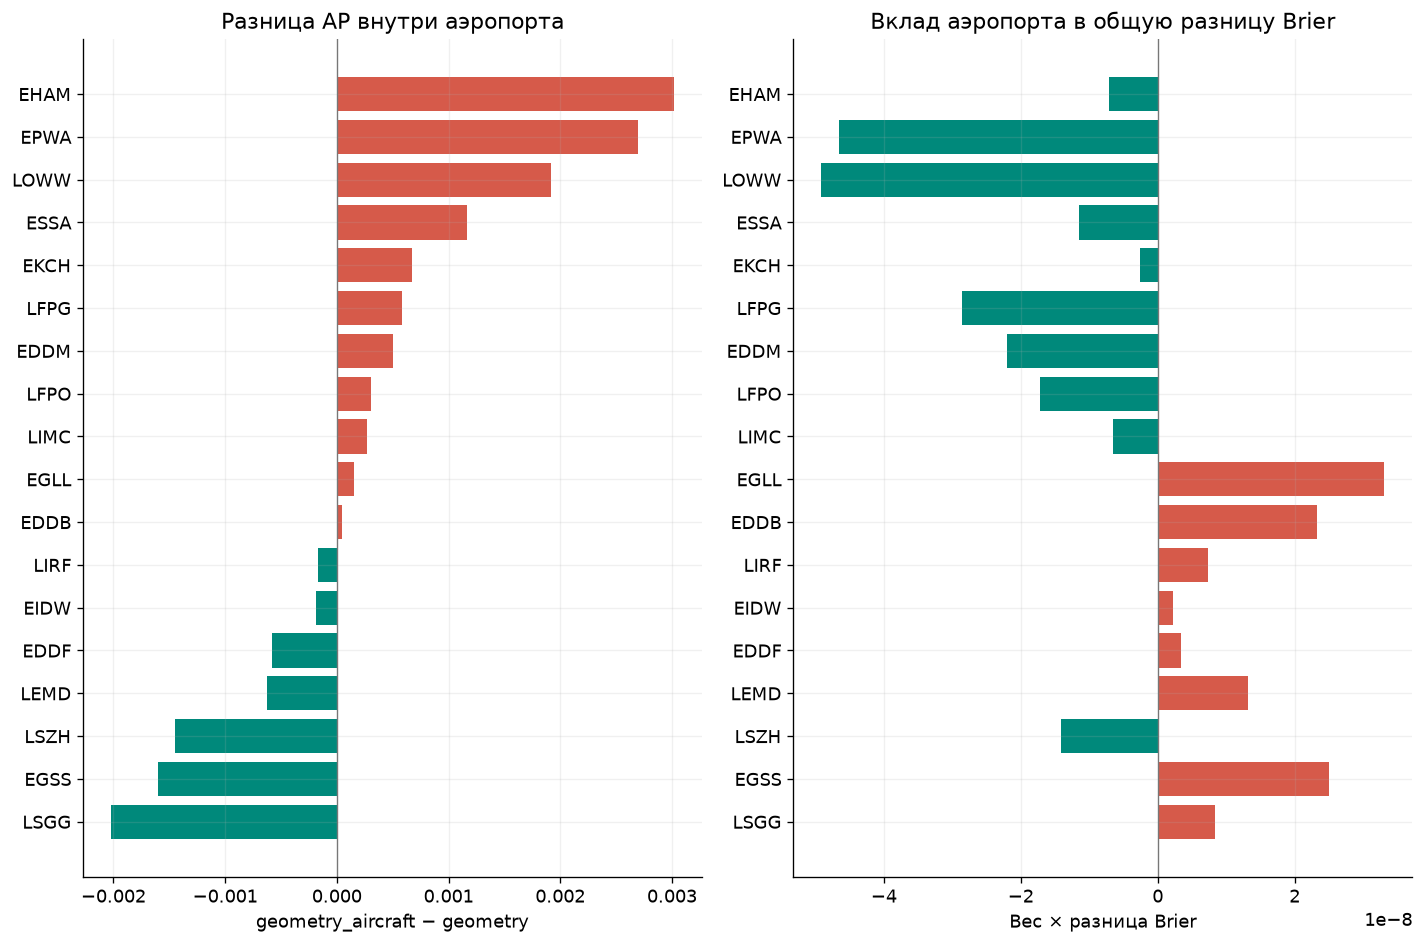

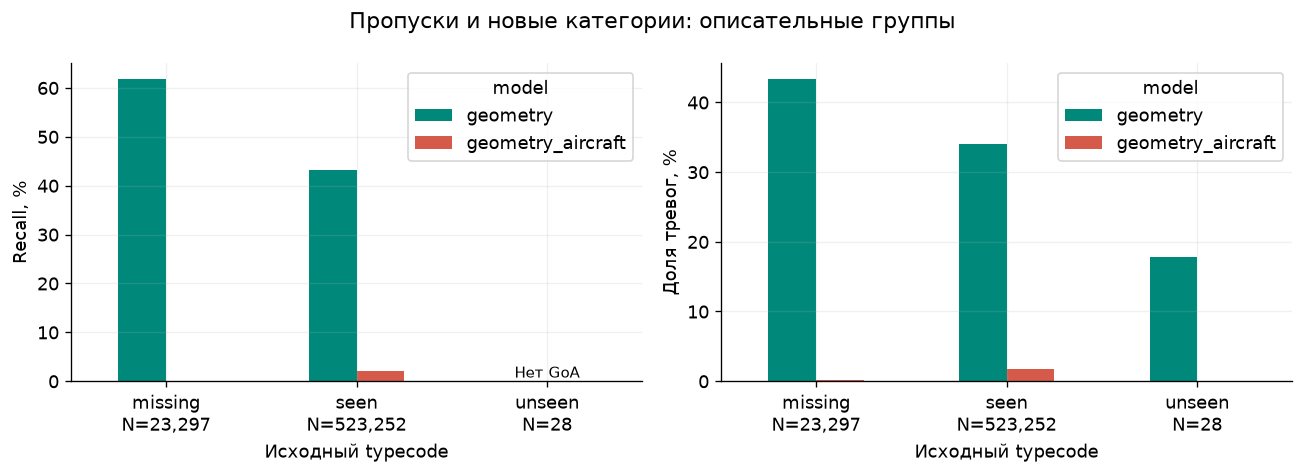

In [4]:
p=airport.pivot(index='group',columns='model',values=['AP','Brier','rows','goa','prevalence'])
comparison=pd.DataFrame({'airport':p.index,'rows':p[('rows','geometry')].to_numpy(),
 'goa':p[('goa','geometry')].to_numpy(),'prevalence':p[('prevalence','geometry')].to_numpy(),
 'geometry_AP':p[('AP','geometry')].to_numpy(),'aircraft_AP':p[('AP','geometry_aircraft')].to_numpy(),
 'delta_AP':(p[('AP','geometry_aircraft')]-p[('AP','geometry')]).to_numpy(),
 'delta_Brier':(p[('Brier','geometry_aircraft')]-p[('Brier','geometry')]).to_numpy()})
comparison['test_weight']=comparison.rows/len(d)
comparison['Brier_contribution']=comparison.test_weight*comparison.delta_Brier
comparison.to_csv(R/'errors_airport_comparison.csv',index=False);display(comparison.style.format(precision=6))
global_delta=float(d.geometry_aircraft_sqerror.mean()-d.geometry_sqerror.mean())
assert np.isclose(comparison.Brier_contribution.sum(),global_delta,atol=1e-14,rtol=1e-7)
q=comparison.sort_values('delta_AP')
fig,axes=plt.subplots(1,2,figsize=(12,8))
axes[0].barh(q.airport,q.delta_AP,color=np.where(q.delta_AP>=0,'#D65A4A','#00897B'))
axes[0].axvline(0,color='#777777',lw=.8);axes[0].set_title('Разница AP внутри аэропорта');axes[0].set_xlabel('geometry_aircraft − geometry')
axes[1].barh(q.airport,q.Brier_contribution,color=np.where(q.Brier_contribution>=0,'#D65A4A','#00897B'))
axes[1].axvline(0,color='#777777',lw=.8);axes[1].set_title('Вклад аэропорта в общую разницу Brier');axes[1].set_xlabel('Вес × разница Brier')
save('30_errors_airport_differences')
q=tables['typecode_state']
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,metric,label in [(axes[0],'recall','Recall, %'),(axes[1],'alert_rate','Доля тревог, %')]:
    q.pivot(index='group',columns='model',values=metric).mul(100).plot.bar(ax=ax,color=[colors[n] for n in names])
    ax.set_ylabel(label);ax.set_xlabel('Исходный typecode');ax.tick_params(axis='x',rotation=0)
    order=sorted(q.group.unique())
    support=q[q.model.eq('geometry')].set_index('group')
    ax.set_xticks(range(len(order)),[f'{g}\nN={int(support.loc[g,"rows"]):,}' for g in order])
    if metric=='recall':
        for i,g in enumerate(order):
            if support.loc[g,'goa']==0:ax.text(i,0,'Нет GoA',ha='center',va='bottom',fontsize=9)
fig.suptitle('Пропуски и новые категории: описательные группы')
save('31_errors_typecode_states')


## 5. Проверки и выводы

Баланс ошибок в каждом разрезе должен совпадать с 08. При нуле TP отношение
FP/TP остается NaN, а не бесконечным или нулевым. Для небольшого unseen-набора
не делаем вывод об эффективности обнаружения. Данные, прогнозы и выбор порогов
проверяются на неизменность до и после анализа.

In [5]:
baseline=pd.read_csv(R/'baseline_metrics.csv')
for field,table in tables.items():
    for n in names:
        a=table[table.model.eq(n)];b=baseline[baseline.split.eq('test')&baseline.model.eq(n)].iloc[0]
        for column in ['rows','goa','tp','fp','fn','tn']:assert int(a[column].sum())==int(b[column])
        assert np.isclose(np.average(a.Brier,weights=a.rows),b.Brier)
assert joint.rows.sum()==len(d) and positive.rows.sum()==int(d.GoA.sum())
assert sha(DATA)==audit['input_sha256'] and sha(prediction_path)==audit['prediction_sha256']
assert sha(selection_path)==selection_hash
verification={'input_sha256':audit['input_sha256'],'prediction_sha256':audit['prediction_sha256'],
 'selection_sha256':selection_hash,'rows_test':len(d),'goa_test':int(d.GoA.sum()),
 'group_balances_passed':True,'Brier_decomposition_passed':True,'input_unchanged':True,
 'prediction_unchanged':True,'thresholds_unchanged':True,'retraining_performed':False,
 'threshold_search_performed':False,'diagnostic_groups':['airport','month','typecode_state','icaoaircrafttype_state']}
(R/'errors_verification.json').write_text(json.dumps(verification,indent=2),encoding='utf-8')
improved=int(comparison.delta_AP.gt(0).sum());worse=int(comparison.delta_AP.lt(0).sum())
type_counts=d.typecode_state.value_counts()
text=f"""# Ошибки фиксированных baseline-моделей

Проверены {len(d):,} test-записей / {int(d.GoA.sum()):,} GoA.
Модели, прогнозы и validation-пороги не изменялись.
Внутри аэропортов AP выше у geometry_aircraft в {improved} группах, ниже в {worse}.
Это описательные знаки без отдельных интервалов; pooled AP не является их суммой.
Общая разница Brier: {global_delta:.12g}; сумма вкладов аэропортов совпадает.

Пересечение тревог:

{joint.to_string(index=False)}

Состояния typecode:

{type_counts.to_string()}

Все балансы ошибок совпадают с 08. Неполные месяцы, разное число событий и
смена состава аэропортов ограничивают сравнение периодов. Unseen-группа мала,
по ней нельзя утверждать надежное качество. Нулевая AP при отсутствии GoA
не подставляется. Историческая доступность остается условной, EGCC отсутствует.
Диагностика не выбирает новый порог или модель. Показатели при разных
validation-порогах не изолируют эффект типов самолетов. Выводы после просмотра
test могут мотивировать только отдельный будущий протокол с независимой
финальной оценкой. Публичные отчеты содержат агрегаты без идентификаторов.
"""
(R/'errors_findings.md').write_text(text,encoding='utf-8');display(Markdown(text))


# Ошибки фиксированных baseline-моделей

Проверены 546,577 test-записей / 1,739 GoA.
Модели, прогнозы и validation-пороги не изменялись.
Внутри аэропортов AP выше у geometry_aircraft в 11 группах, ниже в 7.
Это описательные знаки без отдельных интервалов; pooled AP не является их суммой.
Общая разница Brier: -8.95388825493e-08; сумма вкладов аэропортов совпадает.

Пересечение тревог:

  GoA alert_overlap   rows
False aircraft_only   1484
False          both   8016
False geometry_only 179332
False       neither 356006
 True aircraft_only      6
 True          both     29
 True geometry_only    739
 True       neither    965

Состояния typecode:

typecode_state
seen       523252
missing     23297
unseen         28

Все балансы ошибок совпадают с 08. Неполные месяцы, разное число событий и
смена состава аэропортов ограничивают сравнение периодов. Unseen-группа мала,
по ней нельзя утверждать надежное качество. Нулевая AP при отсутствии GoA
не подставляется. Историческая доступность остается условной, EGCC отсутствует.
Диагностика не выбирает новый порог или модель. Показатели при разных
validation-порогах не изолируют эффект типов самолетов. Выводы после просмотра
test могут мотивировать только отдельный будущий протокол с независимой
финальной оценкой. Публичные отчеты содержат агрегаты без идентификаторов.
